In [3]:
import numpy as np
import scipy.stats as stats
import xarray as xr


# =============================================================================
# RQ1: COMPOUND DROUGHT-HEATWAVE RETURN PERIOD ANALYSIS
# Based directly on supervisor's Return_Period.py
# Period: 1982–2025
# =============================================================================


def compute_compound_return_periods(compound_nc_path, hw_nc_path, fd_nc_path):
    """
    Loads seasonal metrics and performs a bivariate joint return period analysis
    for compound extremes across the historical time series.
    """

    print("=" * 75)
    print("RQ1: CDHW JOINT RETURN PERIOD ANALYSIS")
    print("=" * 75)

    print("\nLoading seasonal matrices...")

    # Keep supervisor's structure
    ds_comp = xr.open_dataset(compound_nc_path)
    ds_hw = xr.open_dataset(hw_nc_path)
    ds_fd = xr.open_dataset(fd_nc_path)

    # -------------------------------------------------------------------------
    # Supervisor's margins:
    # Total Heatwave Duration
    # Total Flash-Drought Duration
    # -------------------------------------------------------------------------

    hw_dur = ds_hw["hw_duration"]
    fd_dur = ds_fd["fd_duration"]

    # Align arrays spatially and temporally
    hw_dur, fd_dur = xr.align(hw_dur, fd_dur, join="inner")

    print("\nInput dimensions:")
    print("Heatwave duration:", hw_dur.dims, hw_dur.shape)
    print("Flash-drought duration:", fd_dur.dims, fd_dur.shape)

    print(
        "\nHarvest years:",
        int(hw_dur.harvest_year.min()),
        "to",
        int(hw_dur.harvest_year.max())
    )

    print(
        "\nFormulating Marginal Empirical Probabilities "
        "(Gringorten plotting position)..."
    )

    # =========================================================================
    # SUPERVISOR'S EMPIRICAL COPULA METHOD
    # =========================================================================

    def estimate_joint_return_periods(hw_axis, fd_axis):
        """
        1D pixel-level processing block to compute joint return periods
        using empirical copula definitions.
        """

        n_years = len(hw_axis)

        if n_years < 5:
            return np.zeros_like(hw_axis, dtype=float), \
                   np.zeros_like(hw_axis, dtype=float)

        # ---------------------------------------------------------------------
        # Rank data to calculate empirical marginal distributions
        # Gringorten plotting position
        # ---------------------------------------------------------------------

        hw_ranks = stats.rankdata(hw_axis, method="average")
        fd_ranks = stats.rankdata(fd_axis, method="average")

        U = (hw_ranks - 0.44) / (n_years + 0.12)
        V = (fd_ranks - 0.44) / (n_years + 0.12)

        # ---------------------------------------------------------------------
        # Empirical joint copula
        # C(u,v) = P(U <= u, V <= v)
        # ---------------------------------------------------------------------

        t_and = np.zeros(n_years, dtype=float)
        t_or = np.zeros(n_years, dtype=float)

        for i in range(n_years):

            both_less_or_equal = np.sum(
                (U <= U[i]) & (V <= V[i])
            )

            C_uv = both_less_or_equal / n_years

            # ================================================================
            # 1. Joint AND Return Period
            # Both hazards exceed current-year levels
            #
            # T_AND = 1 / [1 - u - v + C(u,v)]
            # ================================================================

            prob_and = 1 - U[i] - V[i] + C_uv

            t_and[i] = 1.0 / max(prob_and, 1e-5)

            # ================================================================
            # 2. Joint OR Return Period
            # At least one hazard exceeds current-year levels
            #
            # T_OR = 1 / [1 - C(u,v)]
            # ================================================================

            prob_or = 1 - C_uv

            t_or[i] = 1.0 / max(prob_or, 1e-5)

        return t_and, t_or

    # =========================================================================
    # APPLY ANALYSIS ACROSS EVERY GRID CELL
    # =========================================================================

    print("\nVectorizing return-period analysis across spatial coordinates...")

    return_periods = xr.apply_ufunc(
        estimate_joint_return_periods,
        hw_dur,
        fd_dur,

        input_core_dims=[
            ["harvest_year"],
            ["harvest_year"]
        ],

        output_core_dims=[
            ["harvest_year"],
            ["harvest_year"]
        ],

        vectorize=True,
        dask="parallelized",

        output_dtypes=[
            float,
            float
        ],
    )

    t_and_array, t_or_array = return_periods

    # =========================================================================
    # IMPORTANT:
    # apply_ufunc normally returns:
    #
    # latitude × longitude × harvest_year
    #
    # Put it back into:
    #
    # harvest_year × latitude × longitude
    #
    # This does NOT change the supervisor's method.
    # =========================================================================

    t_and_array = t_and_array.transpose(
        "harvest_year",
        "latitude",
        "longitude"
    )

    t_or_array = t_or_array.transpose(
        "harvest_year",
        "latitude",
        "longitude"
    )

    # =========================================================================
    # CREATE OUTPUT DATASET
    # =========================================================================

    evt_ds = xr.Dataset(
        {
            "return_period_AND": t_and_array,
            "return_period_OR": t_or_array,
        }
    )

    # -------------------------------------------------------------------------
    # Metadata
    # -------------------------------------------------------------------------

    evt_ds["return_period_AND"].attrs[
        "description"
    ] = (
        "Joint return period (years) where BOTH heatwave and "
        "flash-drought durations exceed the current harvest-year levels."
    )

    evt_ds["return_period_AND"].attrs["units"] = "years"

    evt_ds["return_period_OR"].attrs[
        "description"
    ] = (
        "Joint return period (years) where EITHER heatwave or "
        "flash-drought duration exceeds the current harvest-year levels."
    )

    evt_ds["return_period_OR"].attrs["units"] = "years"

    evt_ds.attrs[
        "method"
    ] = (
        "Empirical bivariate copula using Gringorten plotting positions, "
        "following supervisor Return_Period.py"
    )

    evt_ds.attrs["study_period"] = "1982-2025"

    return evt_ds


# =============================================================================
# EXECUTION
# =============================================================================

if __name__ == "__main__":

    # -------------------------------------------------------------------------
    # Compound file
    #
    # This is retained because it occurs in the supervisor's original code.
    # The present return-period calculation does not directly use its variables.
    # Replace this path ONLY if your compound file has a different filename.
    # -------------------------------------------------------------------------

    comp_file = (
        r"C:\Users\franc\south_africa_compound_extremes_summary_1982_2025.nc"
    )

    # -------------------------------------------------------------------------
    # IMPORTANT:
    # We already prepared BOTH hw_duration and fd_duration inside this file.
    #
    # Therefore, the SAME file can safely be supplied for hw_file and fd_file.
    # -------------------------------------------------------------------------

    evt_input_file = (
        r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"
    )

    hw_file = evt_input_file
    fd_file = evt_input_file

    # Output
    output_file = (
        r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc"
    )

    try:

        evt_results = compute_compound_return_periods(
            comp_file,
            hw_file,
            fd_file
        )

        # Save results
        evt_results.to_netcdf(output_file)

        print("\n" + "=" * 75)
        print("RETURN PERIOD ANALYSIS COMPLETED")
        print("=" * 75)

        print("\nOutput variables:")
        print(list(evt_results.data_vars))

        print("\nDimensions:")
        print(dict(evt_results.sizes))

        print("\nHarvest years:")
        print(
            int(evt_results.harvest_year.min()),
            "to",
            int(evt_results.harvest_year.max())
        )

        print("\nSaved:")
        print(output_file)

        print("\nSuccessfully executed multi-hazard return period analysis.")

    except FileNotFoundError as e:

        print("\nFILE NOT FOUND:")
        print(e)

        print(
            "\nPlease check the filenames and paths before running the analysis."
        )

RQ1: CDHW JOINT RETURN PERIOD ANALYSIS

Loading seasonal matrices...


C:\Users\franc\AppData\Local\Temp\ipykernel_63700\122381496.py:27: FutureWarning: In a future version, xarray will not decode the variable 'fd_duration' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds_hw = xr.open_dataset(hw_nc_path)
C:\Users\franc\AppData\Local\Temp\ipykernel_63700\122381496.py:28: FutureWarning: In a future version, xarray will not decode the variable 'fd_duration' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is


Input dimensions:
Heatwave duration: ('harvest_year', 'latitude', 'longitude') (44, 57, 89)
Flash-drought duration: ('harvest_year', 'latitude', 'longitude') (44, 57, 89)

Harvest years: 1982 to 2025

Formulating Marginal Empirical Probabilities (Gringorten plotting position)...

Vectorizing return-period analysis across spatial coordinates...

RETURN PERIOD ANALYSIS COMPLETED

Output variables:
['return_period_AND', 'return_period_OR']

Dimensions:
{'latitude': 57, 'longitude': 89, 'harvest_year': 44}

Harvest years:
1982 to 2025

Saved:
C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc

Successfully executed multi-hazard return period analysis.


In [4]:
import xarray as xr
import numpy as np

evt_file = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc"

evt = xr.open_dataset(evt_file)

print("=" * 75)
print("RQ1: RETURN PERIOD QUALITY CHECK")
print("=" * 75)

for var in ["return_period_AND", "return_period_OR"]:

    print("\n" + "-" * 75)
    print(var)
    print("-" * 75)

    da = evt[var]

    # Work year-by-year to avoid unnecessary memory loading
    values = []

    for year in evt.harvest_year.values:
        arr = da.sel(harvest_year=year).values
        arr = arr[np.isfinite(arr)]
        values.append(arr)

    values = np.concatenate(values)

    print("Finite values:", len(values))
    print("Minimum:", np.min(values))
    print("Median:", np.median(values))
    print("Mean:", np.mean(values))
    print("90th percentile:", np.percentile(values, 90))
    print("95th percentile:", np.percentile(values, 95))
    print("99th percentile:", np.percentile(values, 99))
    print("Maximum:", np.max(values))

    print("Values > 50 years:", np.sum(values > 50))
    print("Values > 100 years:", np.sum(values > 100))
    print("Values >= 100000 years:", np.sum(values >= 100000))

RQ1: RETURN PERIOD QUALITY CHECK

---------------------------------------------------------------------------
return_period_AND
---------------------------------------------------------------------------
Finite values: 223212
Minimum: 1.0380510341582359
Median: 1.9514274225975075
Mean: 4.6862340906569635
90th percentile: 10.75859011305699
95th percentile: 20.865004299226204
99th percentile: 39.78032786885286
Maximum: 43.880650994575355
Values > 50 years: 0
Values > 100 years: 0
Values >= 100000 years: 0

---------------------------------------------------------------------------
return_period_OR
---------------------------------------------------------------------------
Finite values: 223212
Minimum: 1.0232558139534884
Median: 1.6296296296296295
Mean: 1120.2011729917317
90th percentile: 6.2857142857142865
95th percentile: 14.666666666666655
99th percentile: 99999.99999999999
Maximum: 99999.99999999999
Values > 50 years: 2493
Values > 100 years: 2493
Values >= 100000 years: 0


In [5]:
import xarray as xr
import numpy as np

evt_file = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc"

evt = xr.open_dataset(evt_file)

rp_or = evt["return_period_OR"]

# Values generated by the 1e-5 safeguard
boundary = rp_or >= 99999

print("=" * 75)
print("OR RETURN-PERIOD BOUNDARY CHECK")
print("=" * 75)

print("\nTotal boundary values:")
print(int(boundary.sum()))

# Count by harvest year
count_by_year = boundary.sum(dim=["latitude", "longitude"])

print("\nBoundary values by harvest year:")
for year, count in zip(
    evt.harvest_year.values,
    count_by_year.values
):
    if count > 0:
        print(f"{int(year)}: {int(count)} grid cells")

# Percentage of all grid-year observations
total = rp_or.size
boundary_count = int(boundary.sum())

print("\nPercentage of all observations:")
print(f"{100 * boundary_count / total:.2f}%")

# Number of spatial cells affected at least once
affected_cells = boundary.any(dim="harvest_year")

print("\nGrid cells affected at least once:")
print(int(affected_cells.sum()))

print("\nTotal spatial grid cells:")
print(affected_cells.size)

print("\nPercentage of grid cells affected:")
print(f"{100 * int(affected_cells.sum()) / affected_cells.size:.2f}%")

OR RETURN-PERIOD BOUNDARY CHECK

Total boundary values:
2493

Boundary values by harvest year:
1983: 11 grid cells
1986: 2 grid cells
1988: 2 grid cells
1989: 1 grid cells
1992: 48 grid cells
1993: 2 grid cells
1995: 11 grid cells
1998: 6 grid cells
1999: 7 grid cells
2000: 18 grid cells
2002: 9 grid cells
2003: 1 grid cells
2005: 458 grid cells
2006: 2 grid cells
2007: 1 grid cells
2008: 1 grid cells
2009: 8 grid cells
2010: 1 grid cells
2012: 1 grid cells
2013: 3 grid cells
2014: 4 grid cells
2016: 1016 grid cells
2017: 24 grid cells
2019: 304 grid cells
2020: 95 grid cells
2022: 22 grid cells
2023: 65 grid cells
2024: 212 grid cells
2025: 158 grid cells

Percentage of all observations:
1.12%

Grid cells affected at least once:
2406

Total spatial grid cells:
5073

Percentage of grid cells affected:
47.43%


In [6]:
import xarray as xr
import numpy as np
from scipy import stats

evt_input = r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"

ds = xr.open_dataset(evt_input)

hw = ds["hw_duration"]
fd = ds["fd_duration"]

print("=" * 75)
print("EVT IMPLEMENTATION DIAGNOSTIC")
print("=" * 75)

print("\nDataset dimensions:")
print(dict(ds.sizes))

print("\nHeatwave duration")
print("dtype:", hw.dtype)
print("NaNs:", int(hw.isnull().sum()))
print("Zeros:", int((hw == 0).sum()))
print("Positive:", int((hw > 0).sum()))

print("\nFlash-drought duration")
print("dtype:", fd.dtype)
print("NaNs:", int(fd.isnull().sum()))
print("Zeros:", int((fd == 0).sum()))
print("Positive:", int((fd > 0).sum()))

# ============================================================
# YEARS WITH ACTIVITY
# ============================================================

hw_year_activity = (hw > 0).sum(
    dim=["latitude", "longitude"]
)

fd_year_activity = (fd > 0).sum(
    dim=["latitude", "longitude"]
)

print("\n" + "=" * 75)
print("ACTIVE GRID CELLS BY YEAR")
print("=" * 75)

for year in ds.harvest_year.values:

    h = int(hw_year_activity.sel(harvest_year=year))
    f = int(fd_year_activity.sel(harvest_year=year))

    print(
        f"{int(year)}: "
        f"HW = {h:4d} | "
        f"FD = {f:4d}"
    )

# ============================================================
# CHECK THE EMPIRICAL-COPULA BOUNDARY
# ============================================================

boundary_count = 0
valid_pixels = 0

for i in range(hw.sizes["latitude"]):

    for j in range(hw.sizes["longitude"]):

        x = hw[:, i, j].values
        y = fd[:, i, j].values

        valid = np.isfinite(x) & np.isfinite(y)

        x = x[valid]
        y = y[valid]

        n = len(x)

        if n < 5:
            continue

        valid_pixels += 1

        r1 = stats.rankdata(x, method="average")
        r2 = stats.rankdata(y, method="average")

        U = (r1 - 0.44) / (n + 0.12)
        V = (r2 - 0.44) / (n + 0.12)

        for k in range(n):

            C = np.mean(
                (U <= U[k]) &
                (V <= V[k])
            )

            if np.isclose(C, 1.0):
                boundary_count += 1

print("\n" + "=" * 75)
print("EMPIRICAL COPULA CHECK")
print("=" * 75)

print("Valid spatial pixels:", valid_pixels)
print("Number of C(u,v) = 1 cases:", boundary_count)

print("\nIf this number is close to the 2,493 OR boundary")
print("observations found earlier, then we have confirmed")
print("exactly where the 100,000-year values originate.")

C:\Users\franc\AppData\Local\Temp\ipykernel_63700\742566522.py:7: FutureWarning: In a future version, xarray will not decode the variable 'fd_duration' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds = xr.open_dataset(evt_input)


EVT IMPLEMENTATION DIAGNOSTIC

Dataset dimensions:
{'harvest_year': 44, 'latitude': 57, 'longitude': 89}

Heatwave duration
dtype: float32
NaNs: 0
Zeros: 46982
Positive: 176230

Flash-drought duration
dtype: timedelta64[ns]
NaNs: 8844
Zeros: 121192
Positive: 93176

ACTIVE GRID CELLS BY YEAR
1982: HW = 3166 | FD = 2144
1983: HW = 4562 | FD = 2937
1984: HW = 4653 | FD = 2279
1985: HW = 3356 | FD = 1138
1986: HW = 4202 | FD = 1072
1987: HW = 3997 | FD = 1647
1988: HW = 3682 | FD =  611
1989: HW = 2056 | FD =  699
1990: HW = 2899 | FD = 1906
1991: HW = 2955 | FD = 2140
1992: HW = 4403 | FD = 2751
1993: HW = 4064 | FD = 2553
1994: HW = 3560 | FD = 1141
1995: HW = 4101 | FD = 2977
1996: HW = 3213 | FD = 1403
1997: HW = 1766 | FD =  775
1998: HW = 5027 | FD = 2246
1999: HW = 4615 | FD = 1693
2000: HW = 3082 | FD =  614
2001: HW = 3529 | FD = 2290
2002: HW = 4417 | FD = 1394
2003: HW = 4755 | FD = 2886
2004: HW = 3742 | FD = 1655
2005: HW = 4297 | FD = 1221
2006: HW = 2833 | FD = 2100
2007: HW

In [7]:
# Corrected return_period code 

import numpy as np
import scipy.stats as stats
import xarray as xr

# ============================================================
# FILES
# ============================================================

input_file = r"C:\Users\franc\rq1_evt_inputs_1982_2025.nc"

output_file = (
    r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"
)

print("=" * 75)
print("RQ1: CORRECTED CDHW JOINT RETURN PERIOD ANALYSIS")
print("=" * 75)

# ============================================================
# LOAD PREPARED EVT INPUTS
# ============================================================

ds = xr.open_dataset(input_file)

hw_dur = ds["hw_duration"]
fd_dur = ds["fd_duration"]

# Convert timedelta to days if necessary
if np.issubdtype(fd_dur.dtype, np.timedelta64):
    fd_dur = fd_dur / np.timedelta64(1, "D")

fd_dur = fd_dur.astype("float32")

print("\nInput dimensions:")
print("Heatwave:", hw_dur.shape)
print("Flash drought:", fd_dur.shape)

# ============================================================
# PIXEL-LEVEL EMPIRICAL RETURN PERIOD FUNCTION
# ============================================================

def estimate_joint_return_periods(hw_axis, fd_axis):

    # --------------------------------------------------------
    # FIX 1:
    # Use only years where BOTH hazards have valid data
    # --------------------------------------------------------

    valid = (
        np.isfinite(hw_axis) &
        np.isfinite(fd_axis)
    )

    n_valid = np.sum(valid)

    # Create full-length output
    t_and = np.full(
        hw_axis.shape,
        np.nan,
        dtype=float
    )

    t_or = np.full(
        hw_axis.shape,
        np.nan,
        dtype=float
    )

    # Supervisor's minimum-data condition retained
    if n_valid < 5:
        return t_and, t_or

    hw = hw_axis[valid]
    fd = fd_axis[valid]

    n = len(hw)

    # --------------------------------------------------------
    # SUPERVISOR METHOD:
    # Gringorten plotting positions
    # --------------------------------------------------------

    hw_ranks = stats.rankdata(
        hw,
        method="average"
    )

    fd_ranks = stats.rankdata(
        fd,
        method="average"
    )

    U = (hw_ranks - 0.44) / (n + 0.12)
    V = (fd_ranks - 0.44) / (n + 0.12)

    t_and_valid = np.full(n, np.nan)
    t_or_valid = np.full(n, np.nan)

    for i in range(n):

        # ----------------------------------------------------
        # Empirical joint copula
        # ----------------------------------------------------

        both_less_or_equal = np.sum(
            (U <= U[i]) &
            (V <= V[i])
        )

        C_uv = both_less_or_equal / n

        # ----------------------------------------------------
        # AND RETURN PERIOD
        # ----------------------------------------------------

        prob_and = (
            1.0
            - U[i]
            - V[i]
            + C_uv
        )

        if prob_and > 0:
            t_and_valid[i] = 1.0 / prob_and

        # ----------------------------------------------------
        # OR RETURN PERIOD
        # ----------------------------------------------------

        prob_or = 1.0 - C_uv

        # IMPORTANT:
        # Do NOT replace probability = 0 by 1e-5.
        #
        # C = 1 means that the empirical sample cannot
        # estimate a finite OR return period.
        # Leave it as NaN rather than inventing 100,000 years.
        if prob_or > 0:
            t_or_valid[i] = 1.0 / prob_or

    # Put valid calculations back into original positions
    t_and[valid] = t_and_valid
    t_or[valid] = t_or_valid

    return t_and, t_or


# ============================================================
# APPLY ACROSS GRID
# ============================================================

print("\nCalculating empirical joint return periods...")

t_and_array, t_or_array = xr.apply_ufunc(
    estimate_joint_return_periods,
    hw_dur,
    fd_dur,

    input_core_dims=[
        ["harvest_year"],
        ["harvest_year"]
    ],

    output_core_dims=[
        ["harvest_year"],
        ["harvest_year"]
    ],

    vectorize=True,

    output_dtypes=[
        float,
        float
    ],
)

# Put harvest_year first
t_and_array = t_and_array.transpose(
    "harvest_year",
    "latitude",
    "longitude"
)

t_or_array = t_or_array.transpose(
    "harvest_year",
    "latitude",
    "longitude"
)

# ============================================================
# CREATE OUTPUT
# ============================================================

evt_ds = xr.Dataset(
    {
        "return_period_AND": t_and_array,
        "return_period_OR": t_or_array
    }
)

evt_ds["return_period_AND"].attrs[
    "description"
] = (
    "Empirical joint AND return period (years): "
    "both heatwave and flash-drought durations exceed "
    "the harvest-year levels."
)

evt_ds["return_period_OR"].attrs[
    "description"
] = (
    "Empirical joint OR return period (years): "
    "either heatwave or flash-drought duration exceeds "
    "the harvest-year levels. Undefined empirical boundary "
    "cases where C(u,v)=1 are stored as NaN."
)

evt_ds.attrs["method"] = (
    "Empirical copula with Gringorten marginal plotting positions"
)

evt_ds.attrs["note"] = (
    "Supervisor methodology retained. Corrections applied only "
    "for missing-value handling and zero empirical exceedance "
    "probability boundary cases."
)

# ============================================================
# SAVE
# ============================================================

evt_ds.to_netcdf(output_file)

print("\n" + "=" * 75)
print("CORRECTED RETURN PERIOD ANALYSIS COMPLETED")
print("=" * 75)

print("\nSaved:")
print(output_file)

RQ1: CORRECTED CDHW JOINT RETURN PERIOD ANALYSIS

Input dimensions:
Heatwave: (44, 57, 89)
Flash drought: (44, 57, 89)

Calculating empirical joint return periods...


C:\Users\franc\AppData\Local\Temp\ipykernel_63700\3950632915.py:25: FutureWarning: In a future version, xarray will not decode the variable 'fd_duration' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds = xr.open_dataset(input_file)



CORRECTED RETURN PERIOD ANALYSIS COMPLETED

Saved:
C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc


In [8]:
import xarray as xr
import numpy as np

old_file = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc"
new_file = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"

old = xr.open_dataset(old_file)
new = xr.open_dataset(new_file)

print("=" * 80)
print("FINAL EVT QUALITY CHECK: OLD vs CORRECTED")
print("=" * 80)

for var in ["return_period_AND", "return_period_OR"]:

    print("\n" + "=" * 80)
    print(var)
    print("=" * 80)

    old_da = old[var]
    new_da = new[var]

    # ------------------------------------------------------------
    # OLD RESULTS
    # ------------------------------------------------------------
    old_vals = old_da.values
    old_finite = old_vals[np.isfinite(old_vals)]

    print("\nOLD RESULTS")
    print("-" * 50)

    print("Finite values:", old_finite.size)
    print("NaNs:", np.isnan(old_vals).sum())

    if old_finite.size > 0:
        print("Minimum:", np.min(old_finite))
        print("Median:", np.median(old_finite))
        print("Mean:", np.mean(old_finite))
        print("90th percentile:", np.percentile(old_finite, 90))
        print("95th percentile:", np.percentile(old_finite, 95))
        print("99th percentile:", np.percentile(old_finite, 99))
        print("Maximum:", np.max(old_finite))

    print("Values > 50 years:", np.sum(old_vals > 50))
    print("Values > 100 years:", np.sum(old_vals > 100))
    print("Values >= 99999 years:", np.sum(old_vals >= 99999))

    # ------------------------------------------------------------
    # CORRECTED RESULTS
    # ------------------------------------------------------------
    new_vals = new_da.values
    new_finite = new_vals[np.isfinite(new_vals)]

    print("\nCORRECTED RESULTS")
    print("-" * 50)

    print("Finite values:", new_finite.size)
    print("NaNs:", np.isnan(new_vals).sum())

    if new_finite.size > 0:
        print("Minimum:", np.min(new_finite))
        print("Median:", np.median(new_finite))
        print("Mean:", np.mean(new_finite))
        print("90th percentile:", np.percentile(new_finite, 90))
        print("95th percentile:", np.percentile(new_finite, 95))
        print("99th percentile:", np.percentile(new_finite, 99))
        print("Maximum:", np.max(new_finite))

    print("Values > 50 years:", np.sum(new_vals > 50))
    print("Values > 100 years:", np.sum(new_vals > 100))
    print("Values >= 99999 years:", np.sum(new_vals >= 99999))

    # ------------------------------------------------------------
    # COMPARISON WHERE BOTH ARE VALID
    # ------------------------------------------------------------
    common = np.isfinite(old_vals) & np.isfinite(new_vals)

    print("\nOLD vs CORRECTED COMPARISON")
    print("-" * 50)

    print("Common finite observations:", np.sum(common))

    if np.sum(common) > 0:
        difference = np.abs(old_vals[common] - new_vals[common])

        print("Mean absolute difference:", np.mean(difference))
        print("Maximum absolute difference:", np.max(difference))
        print(
            "Exactly / nearly unchanged:",
            np.sum(difference < 1e-10)
        )

print("\n" + "=" * 80)
print("BOUNDARY-CASE CHECK")
print("=" * 80)

or_new = new["return_period_OR"].values

print(
    "Undefined corrected OR cases (NaNs):",
    np.isnan(or_new).sum()
)

print(
    "Remaining >= 99999-year OR values:",
    np.sum(or_new >= 99999)
)

print("\nQuality check complete.")

FINAL EVT QUALITY CHECK: OLD vs CORRECTED

return_period_AND

OLD RESULTS
--------------------------------------------------
Finite values: 223212
NaNs: 0
Minimum: 1.0380510341582359
Median: 1.9514274225975075
Mean: 4.6862340906569635
90th percentile: 10.75859011305699
95th percentile: 20.865004299226204
99th percentile: 39.78032786885286
Maximum: 43.880650994575355
Values > 50 years: 0
Values > 100 years: 0
Values >= 99999 years: 0

CORRECTED RESULTS
--------------------------------------------------
Finite values: 214368
NaNs: 8844
Minimum: 1.0621553007090958
Median: 1.9509567454574692
Mean: 4.5853099368765236
90th percentile: 9.681228805106729
95th percentile: 20.865004299226204
99th percentile: 39.78032786885286
Maximum: 42.948672566372
Values > 50 years: 0
Values > 100 years: 0
Values >= 99999 years: 0

OLD vs CORRECTED COMPARISON
--------------------------------------------------
Common finite observations: 214368
Mean absolute difference: 0.0
Maximum absolute difference: 0.0
Exa

In [9]:
import xarray as xr
import numpy as np
import pandas as pd

# ============================================================
# RQ1: EVT TEMPORAL + SPATIAL SUMMARY
# Identifying the most extreme AND and OR return-period years and their spatial extent.
# ============================================================

evt_file = (
    r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"
)

ds = xr.open_dataset(evt_file)

print("=" * 80)
print("RQ1: CDHW RETURN-PERIOD SUMMARY")
print("=" * 80)

records = []

for year in ds.harvest_year.values:

    for var, label in [
        ("return_period_AND", "AND"),
        ("return_period_OR", "OR")
    ]:

        da = ds[var].sel(harvest_year=year)

        values = da.values
        finite = values[np.isfinite(values)]

        if finite.size == 0:
            continue

        records.append({
            "Harvest_Year": int(year),
            "Type": label,
            "Mean_RP": np.mean(finite),
            "Median_RP": np.median(finite),
            "P95_RP": np.percentile(finite, 95),
            "Maximum_RP": np.max(finite),
            "Valid_Cells": finite.size
        })

summary = pd.DataFrame(records)

# ============================================================
# PRINT TOP YEARS
# ============================================================

for rp_type in ["AND", "OR"]:

    temp = summary[
        summary["Type"] == rp_type
    ].copy()

    print("\n" + "=" * 80)
    print(f"{rp_type} RETURN PERIOD")
    print("=" * 80)

    print("\nTop 10 years by spatial mean:")
    print(
        temp.sort_values(
            "Mean_RP",
            ascending=False
        )[
            [
                "Harvest_Year",
                "Mean_RP",
                "Median_RP",
                "P95_RP",
                "Maximum_RP",
                "Valid_Cells"
            ]
        ].head(10).to_string(index=False)
    )

# ============================================================
# RETURN-PERIOD THRESHOLD EXTENT
# ============================================================

print("\n" + "=" * 80)
print("SPATIAL EXTENT OF RETURN-PERIOD THRESHOLDS")
print("=" * 80)

extent_records = []

for year in ds.harvest_year.values:

    for var, label in [
        ("return_period_AND", "AND"),
        ("return_period_OR", "OR")
    ]:

        da = ds[var].sel(harvest_year=year)

        valid = np.isfinite(da.values)
        values = da.values

        n_valid = valid.sum()

        if n_valid == 0:
            continue

        row = {
            "Harvest_Year": int(year),
            "Type": label,
            "Valid_Cells": int(n_valid)
        }

        for threshold in [2, 5, 10, 20]:

            count = np.sum(
                valid &
                (values >= threshold)
            )

            row[f"Cells_RP_ge_{threshold}"] = int(count)

            row[f"Percent_RP_ge_{threshold}"] = (
                100 * count / n_valid
            )

        extent_records.append(row)

extent = pd.DataFrame(extent_records)

# ============================================================
# FIND YEARS WITH LARGEST EXTENT OF >=10-YEAR RP
# ============================================================

for rp_type in ["AND", "OR"]:

    temp = extent[
        extent["Type"] == rp_type
    ].copy()

    print("\n" + "-" * 80)
    print(f"{rp_type}: largest spatial extent of RP >= 10 years")
    print("-" * 80)

    print(
        temp.sort_values(
            "Percent_RP_ge_10",
            ascending=False
        )[
            [
                "Harvest_Year",
                "Cells_RP_ge_10",
                "Percent_RP_ge_10",
                "Cells_RP_ge_20",
                "Percent_RP_ge_20"
            ]
        ].head(10).to_string(index=False)
    )

# ============================================================
# SAVE TABLES
# ============================================================

summary_file = (
    r"C:\Users\franc\rq1_evt_temporal_summary_1982_2025.csv"
)

extent_file = (
    r"C:\Users\franc\rq1_evt_spatial_extent_1982_2025.csv"
)

summary.to_csv(summary_file, index=False)
extent.to_csv(extent_file, index=False)

print("\n" + "=" * 80)
print("SAVED")
print("=" * 80)

print(summary_file)
print(extent_file)

RQ1: CDHW RETURN-PERIOD SUMMARY

AND RETURN PERIOD

Top 10 years by spatial mean:
 Harvest_Year   Mean_RP  Median_RP    P95_RP  Maximum_RP  Valid_Cells
         2016 19.202052  20.865004 40.021501   42.165074         4872
         2019 17.345330  14.215583 39.682747   41.730009         4872
         2024 14.670965   8.724070 40.578595   42.386026         4872
         2020  9.784960   7.881130 27.700913   41.515825         4872
         1992  8.354869   3.656721 39.489015   41.946413         4872
         2025  7.373436   5.457326 21.137631   42.165074         4872
         1983  7.235780   3.986201 21.165286   41.303830         4872
         2017  6.849658   4.394621 21.000433   41.622642         4872
         1995  6.462959   3.515029 21.000433   41.946413         4872
         2013  5.998648   2.750234 20.973207   41.946413         4872

OR RETURN PERIOD

Top 10 years by spatial mean:
 Harvest_Year   Mean_RP  Median_RP    P95_RP  Maximum_RP  Valid_Cells
         2016 17.731919  14.6

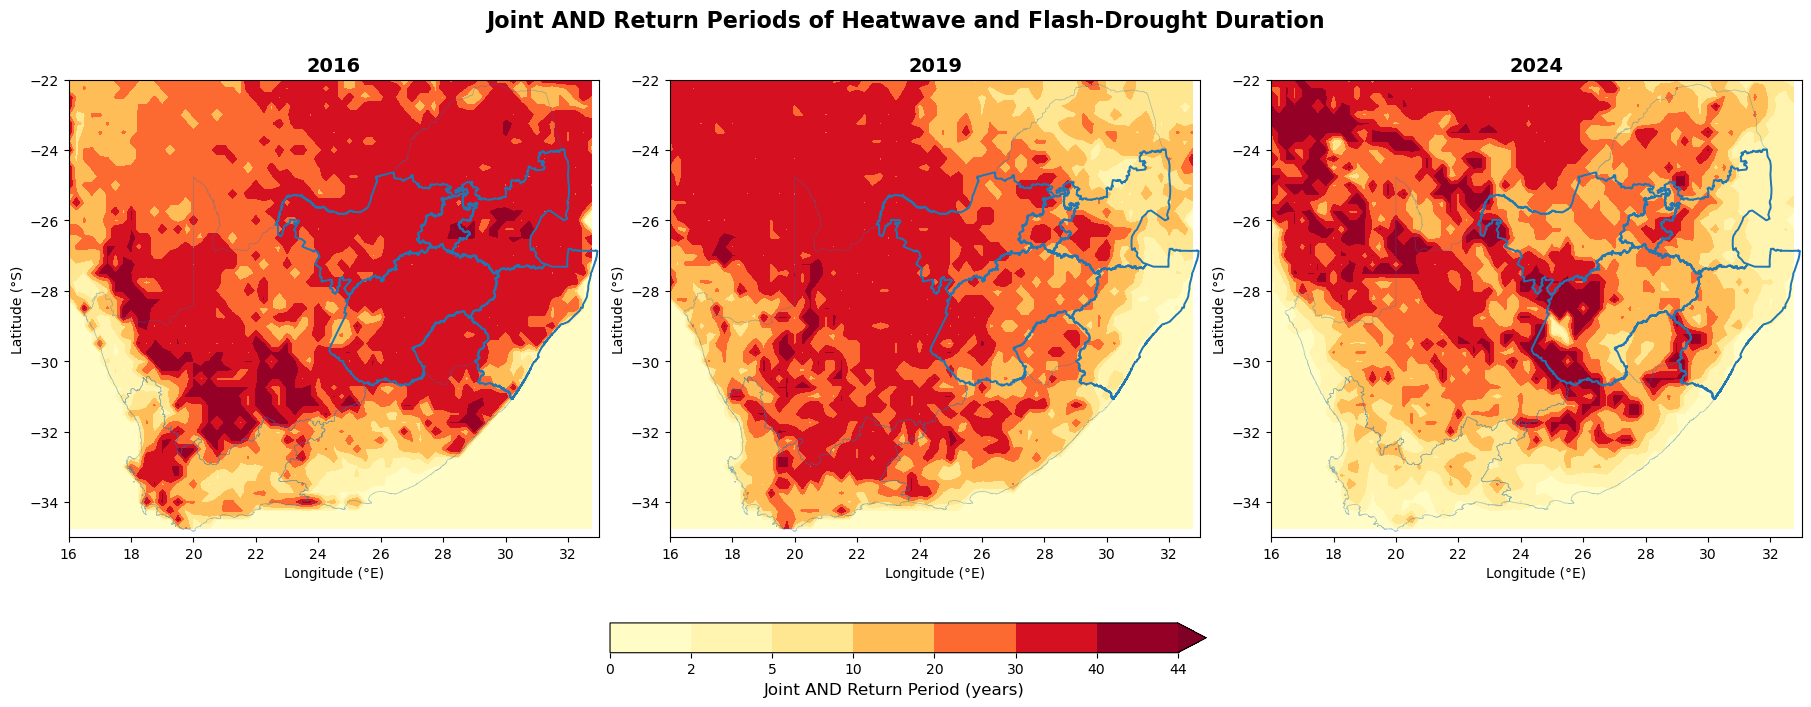


Saved:
C:\Users\franc\rq1_evt_AND_maps_2016_2019_2024.png
C:\Users\franc\rq1_evt_AND_maps_2016_2019_2024.svg


In [13]:
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np

# ============================================================
# RQ1: SPATIAL MAPS OF JOINT AND RETURN PERIODS
# ============================================================

evt_file = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"

# IMPORTANT:
# Replace this with the SAME province boundary file/path
# that successfully gave you the clear province map earlier.
province_file =r"C:\Users\franc\South_Africa_Provinces\South_Africa_Provinces.gpkg"

# ============================================================
# OPEN DATA
# ============================================================

ds = xr.open_dataset(evt_file)

provinces = gpd.read_file(province_file)

study_names = [
    "Mpumalanga",
    "North West",
    "Gauteng",
    "Free State",
    "KwaZulu-Natal"
]

study_provinces = provinces[
    provinces["ProvinceName"].isin(study_names)
].copy()

# Ensure geographic coordinates
if study_provinces.crs is not None:
    study_provinces = study_provinces.to_crs("EPSG:4326")

# ============================================================
# YEARS IDENTIFIED FROM EVT ANALYSIS
# ============================================================

years = [2016, 2019, 2024]

# Common scale so the three years are directly comparable
levels = np.arange(0, 46, 2)

# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 7),
    constrained_layout=True
)

contour = None
levels = [0, 2, 5, 10, 20, 30, 40, 44]

for ax, year in zip(axes, years):

    da = ds["return_period_AND"].sel(
        harvest_year=year
    )

    contour = ax.contourf(
        ds["longitude"],
        ds["latitude"],
        da,
        levels=levels,
        cmap="YlOrRd", 
        extend="max"
    )

    # All province boundaries faintly
    provinces.boundary.plot(
        ax=ax,
        linewidth=0.5,
        alpha=0.4
    )

    # Study provinces clearly
    study_provinces.boundary.plot(
        ax=ax,
        linewidth=1.4
    )

    ax.set_title(
        f"{year}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°S)")

    # Focus map on South Africa
    ax.set_xlim(16, 33)
    ax.set_ylim(-35, -22)

# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    contour,
    ax=axes,
    orientation="horizontal",
    fraction=0.06,
    pad=0.08
)

cbar.set_label(
    "Joint AND Return Period (years)",
    fontsize=12
)

fig.suptitle(
    "Joint AND Return Periods of Heatwave and Flash-Drought Duration",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# SAVE HIGH QUALITY
# ============================================================

png_file = r"C:\Users\franc\rq1_evt_AND_maps_2016_2019_2024.png"
svg_file = r"C:\Users\franc\rq1_evt_AND_maps_2016_2019_2024.svg"

plt.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    svg_file,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(png_file)
print(svg_file)

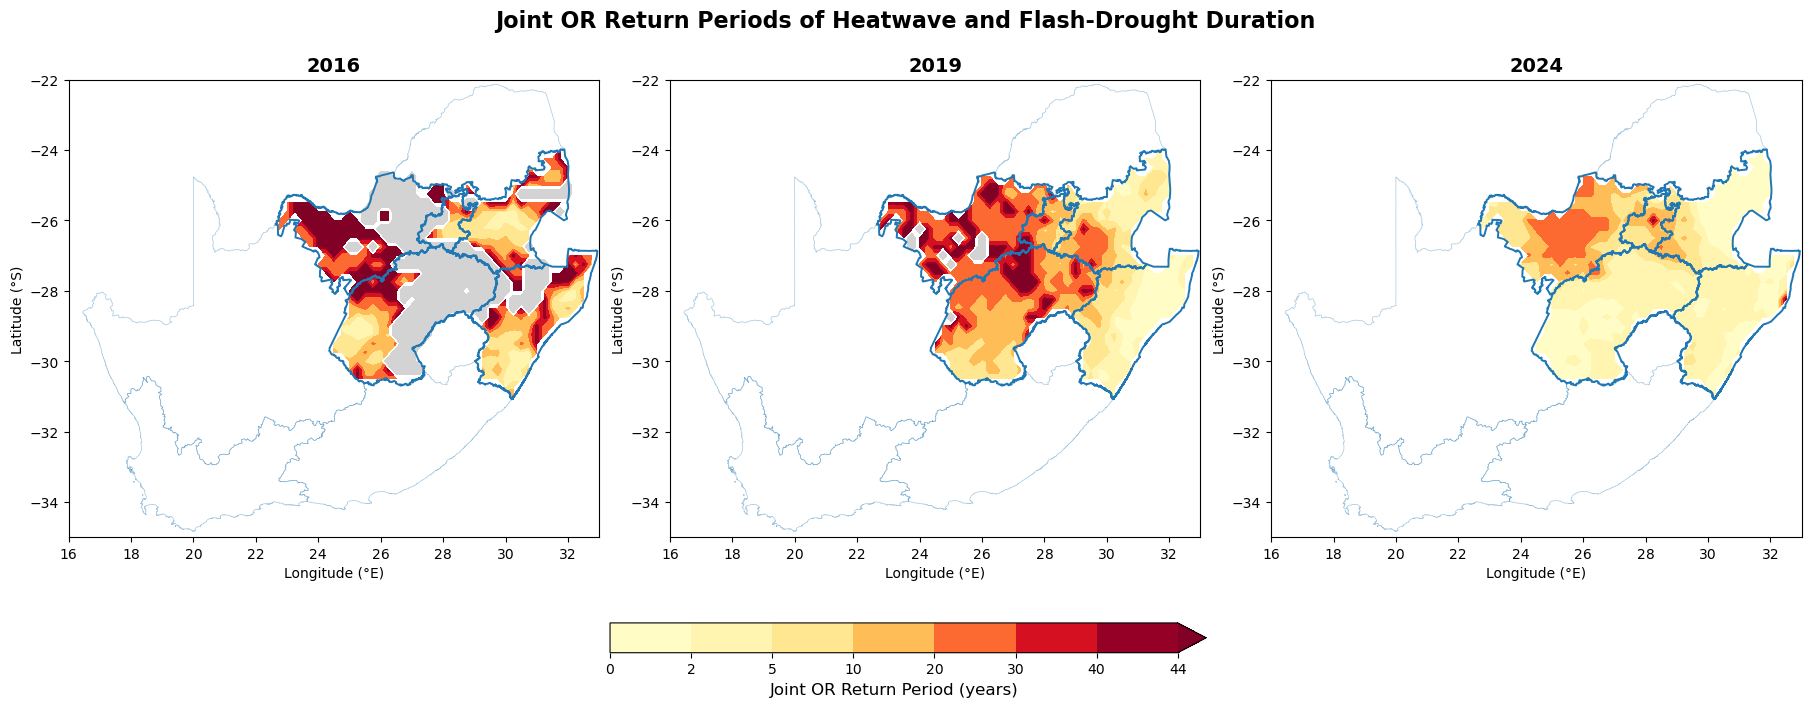


Saved:
C:\Users\franc\rq1_evt_OR_maps_2016_2019_2024.png
C:\Users\franc\rq1_evt_OR_maps_2016_2019_2024.svg


In [20]:
# ============================================================
# RQ1: SPATIAL MAPS OF JOINT OR RETURN PERIODS
# ============================================================

years = [2016, 2019, 2024]

# Same intervals as AND maps
levels = [0, 2, 5, 10, 20, 30, 40, 44]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 7),
    constrained_layout=True
)

contour = None

for ax, year in zip(axes, years):

    da = ds["return_period_OR"].sel(harvest_year=year)
    # Keep only the five study provinces
    inside_study = ~np.isnan(study_mask)

    # Actual EVT data inside study provinces
    da_study = da.where(inside_study)

    # Plot only valid return-period values
    contour = ax.contourf(
        ds["longitude"],
        ds["latitude"],
        da_study,
        levels=[0, 2, 5, 10, 20, 30, 40, 44],
        cmap="YlOrRd",
        extend="max"
)
    undefined_inside = inside_study & np.isnan(da)

    ax.contourf(
        ds["longitude"],
        ds["latitude"],
        undefined_inside.astype(int),
        levels=[0.5, 1.5],
        colors=["lightgrey"]
)

    # All SA provincial boundaries
    provinces.boundary.plot(
        ax=ax,
        linewidth=0.5,
        alpha=0.4
    )

    # Five study provinces
    study_provinces.boundary.plot(
        ax=ax,
        linewidth=1.4
    )

    ax.set_title(
        str(year),
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°S)")

    ax.set_xlim(16, 33)
    ax.set_ylim(-35, -22)

# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    contour,
    ax=axes,
    orientation="horizontal",
    fraction=0.06,
    pad=0.08
)

cbar.set_label(
    "Joint OR Return Period (years)",
    fontsize=12
)

fig.suptitle(
    "Joint OR Return Periods of Heatwave and Flash-Drought Duration",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# SAVE
# ============================================================

png_file = r"C:\Users\franc\rq1_evt_OR_maps_2016_2019_2024.png"
svg_file = r"C:\Users\franc\rq1_evt_OR_maps_2016_2019_2024.svg"

plt.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    svg_file,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(png_file)
print(svg_file)

In [17]:
import numpy as np
import regionmask

# ============================================================
# STUDY PROVINCES
# ============================================================

study_names = [
    "Mpumalanga",
    "North West",
    "Gauteng",
    "Free State",
    "KwaZulu-Natal"
]

study_provinces = provinces[
    provinces["ProvinceName"].isin(study_names)
].copy()

print("Study provinces:")
print(study_provinces["ProvinceName"].tolist())

# ============================================================
# CREATE MASK ON EVT GRID
# ============================================================

regions = regionmask.from_geopandas(
    study_provinces,
    names="ProvinceName"
)

study_mask = regions.mask(
    ds["longitude"],
    ds["latitude"]
)

print("\nMask created successfully.")
print("Mask shape:", study_mask.shape)
print("Unique mask values:")
print(np.unique(study_mask.values))

Study provinces:
['Mpumalanga', 'North West', 'Gauteng', 'Free State', 'KwaZulu-Natal']

Mask created successfully.
Mask shape: (57, 89)
Unique mask values:
[ 1.  2.  4.  5.  6. nan]


In [21]:
import os

print("=" * 80)
print("SEARCHING FOR MAIZE / YIELD / SPAM FILES")
print("=" * 80)

search_folder = r"C:\Users\franc"

keywords = [
    "maize",
    "yield",
    "spam",
    "crop",
    "production"
]

extensions = (
    ".csv", ".xlsx", ".xls",
    ".nc", ".nc4",
    ".tif", ".tiff"
)

found = []

for root, dirs, files in os.walk(search_folder):
    for file in files:
        name = file.lower()

        if (
            any(k in name for k in keywords)
            and name.endswith(extensions)
        ):
            path = os.path.join(root, file)
            found.append(path)

for path in found:
    print(path)

print("\n" + "=" * 80)
print("NUMBER FOUND:", len(found))
print("=" * 80)

SEARCHING FOR MAIZE / YIELD / SPAM FILES
C:\Users\franc\south_africa_maize_season_heatwaves_1981_2025.nc
C:\Users\franc\south_africa_maize_season_heatwaves_1981_2025_updated.nc

NUMBER FOUND: 2


In [22]:
import os

folder = r"C:\Users\franc"

print("=" * 80)
print("SEARCHING FOR GLEAM FILES")
print("=" * 80)

keywords = [
    "gleam",
    "ep_",
    "potential",
    "evap"
]

extensions = (".nc", ".nc4")

found = []

for root, dirs, files in os.walk(folder):
    for file in files:
        name = file.lower()

        if (
            any(k in name for k in keywords)
            and name.endswith(extensions)
        ):
            found.append(os.path.join(root, file))

for f in sorted(found):
    print(f)

print("\n" + "=" * 80)
print("NUMBER OF FILES:", len(found))
print("=" * 80)

SEARCHING FOR GLEAM FILES
C:\Users\franc\2015\E_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Eb_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Ec_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Ei_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Ep_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Ep_aero_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Ep_rad_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Es_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Et_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\Ew_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\H_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\SMrz_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\SMs_2015_GLEAM_v4.3a.nc
C:\Users\franc\2015\S_2015_GLEAM_v4.3a.nc
C:\Users\franc\2016\E_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Eb_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Ec_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Ei_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Ep_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Ep_aero_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Ep_rad_2016_GLEAM_v4.3a.nc
C:\Users\franc\2016\Es_2016_GLEAM_v4.3a.nc
C:\Users\fr

In [1]:
from pathlib import Path

ROOT = Path(r"C:\Users\franc")

keywords = [
    "return",
    "evt",
    "tand",
    "tor",
    "10year",
    "50year",
    "100year",
    "10_year",
    "50_year",
    "100_year"
]

matches = []

for f in ROOT.rglob("*"):
    if f.is_file():
        name = f.name.lower()

        if any(k in name for k in keywords):
            # Skip software/system folders
            path_lower = str(f).lower()

            if not any(x in path_lower for x in [
                "anaconda3",
                "appdata",
                ".conda"
            ]):
                matches.append(f)

print("=" * 80)
print("SEARCHING FOR EVT / RETURN-LEVEL OUTPUTS")
print("=" * 80)

for f in matches:
    print(f)

print("\nNumber found:", len(matches))

SEARCHING FOR EVT / RETURN-LEVEL OUTPUTS
C:\Users\franc\.python_history
C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc
C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc
C:\Users\franc\rq1_evt_AND_maps_2016_2019_2024.png
C:\Users\franc\rq1_evt_AND_maps_2016_2019_2024.svg
C:\Users\franc\rq1_evt_inputs_1982_2025.nc
C:\Users\franc\rq1_evt_OR_maps_2016_2019_2024.png
C:\Users\franc\rq1_evt_OR_maps_2016_2019_2024.svg
C:\Users\franc\rq1_evt_spatial_extent_1982_2025.csv
C:\Users\franc\rq1_evt_temporal_summary_1982_2025.csv
C:\Users\franc\.spyder-py3\history.py
C:\Users\franc\.spyder-py3\history_internal.py
C:\Users\franc\.spyder-py3\pdb_history.sqlite
C:\Users\franc\Documents\.Rhistory
C:\Users\franc\Documents\ICI3D_RTutorial_4.R.txt
C:\Users\franc\Documents\TUTORIAL 3 QUESTION 2.xlsx
C:\Users\franc\Documents\tutorial1 2022.xlsx
C:\Users\franc\Documents\tutorial5.csv
C:\Users\franc\Downloads\Historic_WGO_Production_Info_2026-07-31.xlsx
C:\Users\franc\Downloads\SCHOLARSHIPS FOR 

In [2]:
from pathlib import Path

ROOT = Path(r"C:\Users\franc")

keywords = [
    "evt", "return", "pot",
    "tand", "tor", "joint",
    "gev", "gpd"
]

extensions = {
    ".csv", ".nc", ".xlsx",
    ".pkl", ".npy", ".npz",
    ".ipynb", ".py"
}

matches = []

for f in ROOT.rglob("*"):
    if (
        f.is_file()
        and f.suffix.lower() in extensions
        and any(k in f.name.lower() for k in keywords)
    ):
        path = str(f).lower()

        if not any(x in path for x in [
            "anaconda3",
            "appdata",
            ".conda"
        ]):
            matches.append(f)

print("=" * 80)
print("EVT / RETURN-LEVEL FILES")
print("=" * 80)

for f in matches:
    print(f)

print("\nNumber found:", len(matches))

EVT / RETURN-LEVEL FILES
C:\Users\franc\rq1_cdhw_return_periods_1982_2025.nc
C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc
C:\Users\franc\rq1_evt_inputs_1982_2025.nc
C:\Users\franc\rq1_evt_spatial_extent_1982_2025.csv
C:\Users\franc\rq1_evt_temporal_summary_1982_2025.csv
C:\Users\franc\.spyder-py3\history.py
C:\Users\franc\.spyder-py3\history_internal.py
C:\Users\franc\Documents\TUTORIAL 3 QUESTION 2.xlsx
C:\Users\franc\Documents\tutorial1 2022.xlsx
C:\Users\franc\Documents\tutorial5.csv
C:\Users\franc\Downloads\Historic_WGO_Production_Info_2026-07-31.xlsx
C:\Users\franc\Downloads\Datasets\CDHW_SA_Project\CDHW_SA_Project\RETURNPERIODII.ipynb
C:\Users\franc\Downloads\Datasets\CDHW_SA_Project\CDHW_SA_Project\Return_Period.py
C:\Users\franc\Downloads\Datasets\CDHW_SA_Project\CDHW_SA_Project\.ipynb_checkpoints\RETURNPERIODII-checkpoint.ipynb
C:\Users\franc\Downloads\Datasets\CDHW_SA_Project\CDHW_SA_Project\.ipynb_checkpoints\Return_Period-checkpoint.py
C:\Users\franc\Docume

In [4]:
# ============================================================
# CHECK RETURN-LEVEL DIMENSIONS WITHOUT PRINTING ds
# ============================================================

print("=" * 70)
print("RETURN LEVEL DIMENSIONS")
print("=" * 70)

# Dimensions
print("\nDimensions:")
for name, size in ds.sizes.items():
    print(f"{name}: {size}")

# Coordinate names
print("\n" + "=" * 70)
print("COORDINATES")
print("=" * 70)

print(list(ds.coords))

# Print coordinate values safely
for coord in ds.coords:
    try:
        values = ds[coord].values

        print(f"\n{coord}:")
        print("Shape:", values.shape)

        # Don't dump thousands of lat/lon values
        if values.size <= 100:
            print("Values:", values)
        else:
            print("First 10:", values.ravel()[:10])
            print("Last 10 :", values.ravel()[-10:])

    except Exception as e:
        print(f"\nCould not read {coord}: {e}")

# Variables
print("\n" + "=" * 70)
print("DATA VARIABLES")
print("=" * 70)

for var in ds.data_vars:
    print(f"{var}:")
    print("  dimensions:", ds[var].dims)
    print("  shape     :", ds[var].shape)

RETURN LEVEL DIMENSIONS

Dimensions:
harvest_year: 44
latitude: 57
longitude: 89

COORDINATES
['number', 'latitude', 'longitude', 'harvest_year']

number:
Shape: ()
Values: 0

latitude:
Shape: (57,)
Values: [-21.   -21.25 -21.5  -21.75 -22.   -22.25 -22.5  -22.75 -23.   -23.25
 -23.5  -23.75 -24.   -24.25 -24.5  -24.75 -25.   -25.25 -25.5  -25.75
 -26.   -26.25 -26.5  -26.75 -27.   -27.25 -27.5  -27.75 -28.   -28.25
 -28.5  -28.75 -29.   -29.25 -29.5  -29.75 -30.   -30.25 -30.5  -30.75
 -31.   -31.25 -31.5  -31.75 -32.   -32.25 -32.5  -32.75 -33.   -33.25
 -33.5  -33.75 -34.   -34.25 -34.5  -34.75 -35.  ]

longitude:
Shape: (89,)
Values: [11.   11.25 11.5  11.75 12.   12.25 12.5  12.75 13.   13.25 13.5  13.75
 14.   14.25 14.5  14.75 15.   15.25 15.5  15.75 16.   16.25 16.5  16.75
 17.   17.25 17.5  17.75 18.   18.25 18.5  18.75 19.   19.25 19.5  19.75
 20.   20.25 20.5  20.75 21.   21.25 21.5  21.75 22.   22.25 22.5  22.75
 23.   23.25 23.5  23.75 24.   24.25 24.5  24.75 25.   25.25 2

In [9]:
import xarray as xr
import numpy as np

# ============================================================
# 1. LOAD CORRECTED DURATION RETURN PERIODS
# ============================================================

FILE = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"

ds = xr.open_dataset(FILE)

# ============================================================
# 2. AVERAGE ACROSS ALL HARVEST YEARS
# ============================================================

mean_AND = ds["return_period_AND"].mean(
    dim="harvest_year",
    skipna=True
)

mean_OR = ds["return_period_OR"].mean(
    dim="harvest_year",
    skipna=True
)

print("=" * 75)
print("MEAN DURATION RETURN PERIODS: 1982–2025")
print("=" * 75)

for name, da in [
    ("AND", mean_AND),
    ("OR", mean_OR)
]:
    values = da.values
    finite = values[np.isfinite(values)]

    print(f"\n{name}")
    print("Grid cells:", len(finite))
    print("Minimum:", np.min(finite))
    print("Median :", np.median(finite))
    print("Mean   :", np.mean(finite))
    print("Maximum:", np.max(finite))

MEAN DURATION RETURN PERIODS: 1982–2025

AND
Grid cells: 4872
Minimum: 1.4529304859713514
Median : 5.486503873956162
Mean   : 4.585309936876524
Maximum: 9.319200683486237

OR
Grid cells: 4872
Minimum: 1.5602260791582703
Median : 3.2128058133049207
Mean   : 3.4142906166966336
Maximum: 7.3303413572691465


In [10]:
# ============================================================
# 3. SAVE MEAN DURATION RETURN PERIOD
# ============================================================

out = xr.Dataset(
    {
        "mean_return_period_AND": mean_AND,
        "mean_return_period_OR": mean_OR
    }
)

out["mean_return_period_AND"].attrs = {
    "long_name": "Mean joint AND return period for heatwave and flash drought duration",
    "units": "years"
}

out["mean_return_period_OR"].attrs = {
    "long_name": "Mean joint OR return period for heatwave and flash drought duration",
    "units": "years"
}

out.attrs["period"] = "1982-2025"
out.attrs["description"] = (
    "Mean joint return periods calculated by averaging annual "
    "return periods over all harvest years."
)

OUTPUT = r"C:\Users\franc\rq1_mean_duration_return_period_1982_2025.nc"

out.to_netcdf(OUTPUT)

print("Saved:")
print(OUTPUT)

Saved:
C:\Users\franc\rq1_mean_duration_return_period_1982_2025.nc


Plot scale: 1.0 to 9.0 years


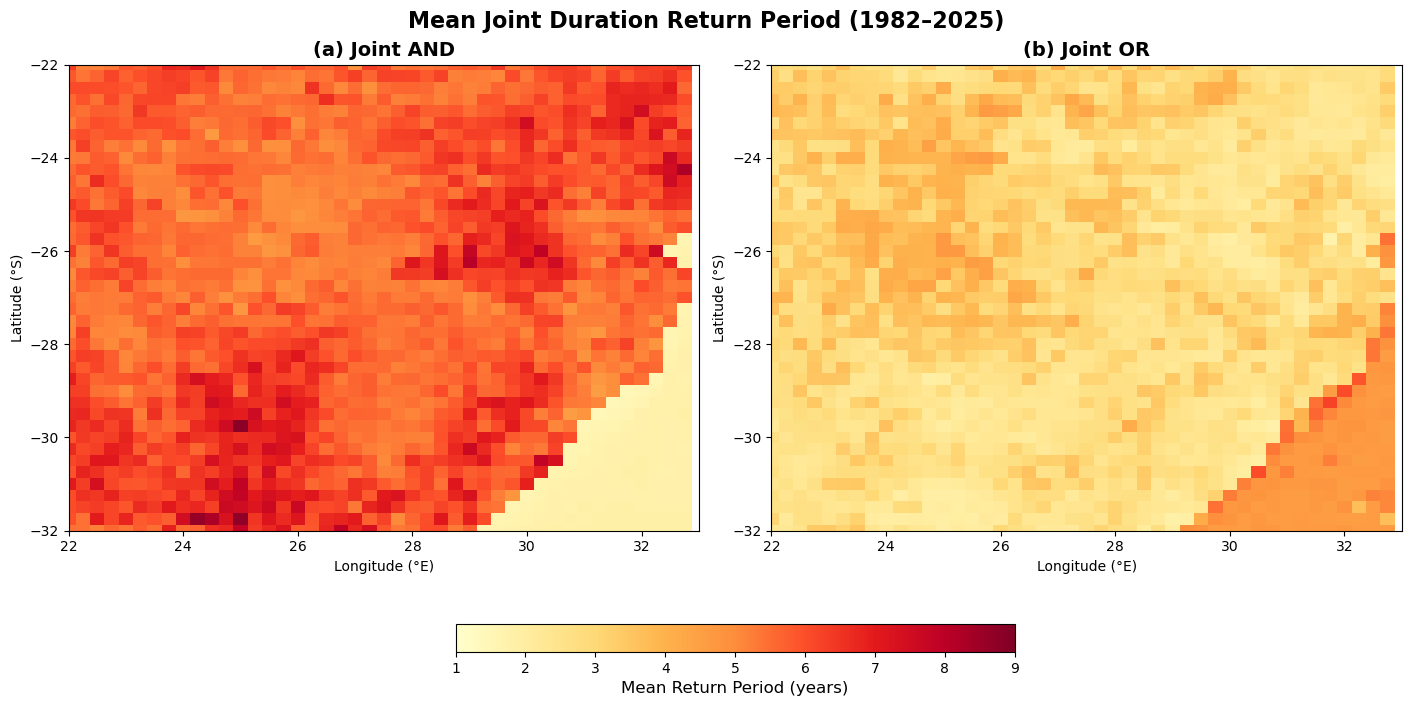


Saved:
C:\Users\franc\mean_duration_return_period_1982_2025.png


In [11]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD RETURN PERIOD DATA
# ============================================================

FILE = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"

ds = xr.open_dataset(FILE)

mean_AND = ds["return_period_AND"].mean(
    dim="harvest_year",
    skipna=True
)

mean_OR = ds["return_period_OR"].mean(
    dim="harvest_year",
    skipna=True
)

# ============================================================
# ZOOM TO STUDY REGION
# Mpumalanga, Gauteng, North West,
# Free State and KwaZulu-Natal
# ============================================================

lon_min, lon_max = 22.0, 33.0
lat_min, lat_max = -32.0, -22.0

AND_zoom = mean_AND.sel(
    longitude=slice(lon_min, lon_max),
    latitude=slice(lat_max, lat_min)
)

OR_zoom = mean_OR.sel(
    longitude=slice(lon_min, lon_max),
    latitude=slice(lat_max, lat_min)
)

# ============================================================
# COMMON SCALE
# ============================================================

combined = np.concatenate([
    AND_zoom.values[np.isfinite(AND_zoom.values)],
    OR_zoom.values[np.isfinite(OR_zoom.values)]
])

vmin = np.floor(np.nanmin(combined))
vmax = np.ceil(np.nanmax(combined))

print("Plot scale:", vmin, "to", vmax, "years")

# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 7),
    constrained_layout=True
)

# ---------------- AND ----------------

p1 = axes[0].pcolormesh(
    AND_zoom.longitude,
    AND_zoom.latitude,
    AND_zoom,
    shading="auto",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title(
    "(a) Joint AND",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Latitude (°S)")

axes[0].set_xlim(lon_min, lon_max)
axes[0].set_ylim(lat_min, lat_max)

# ---------------- OR ----------------

p2 = axes[1].pcolormesh(
    OR_zoom.longitude,
    OR_zoom.latitude,
    OR_zoom,
    shading="auto",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title(
    "(b) Joint OR",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°S)")

axes[1].set_xlim(lon_min, lon_max)
axes[1].set_ylim(lat_min, lat_max)

# ============================================================
# SHARED COLORBAR
# ============================================================

cbar = fig.colorbar(
    p2,
    ax=axes,
    orientation="horizontal",
    fraction=0.06,
    pad=0.10
)

cbar.set_label(
    "Mean Return Period (years)",
    fontsize=12
)

# ============================================================
# MAIN TITLE
# ============================================================

fig.suptitle(
    "Mean Joint Duration Return Period (1982–2025)",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# SAVE
# ============================================================

OUTPUT = r"C:\Users\franc\mean_duration_return_period_1982_2025.png"

plt.savefig(
    OUTPUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(OUTPUT)

In [12]:
import geopandas as gpd

province_file = r"C:\Users\franc\South_Africa_Provinces\South_Africa_Provinces.gpkg"

provinces_test = gpd.read_file(province_file)

print(provinces_test.columns)
print(provinces_test.head())

Index(['OBJECTID', 'ProvinceCode', 'ProvinceName', 'Country', 'Timestamp',
       'Shape_Length', 'Shape_Area', 'geometry'],
      dtype='object')
   OBJECTID ProvinceCode   ProvinceName       Country      Timestamp  \
0         1          LIM        Limpopo  South Africa  1471392000000   
1         2           MP     Mpumalanga  South Africa  1471392000000   
2         3           NW     North West  South Africa  1471392000000   
3         4           NC  Northern Cape  South Africa  1471392000000   
4         5           GT        Gauteng  South Africa  1471392000000   

   Shape_Length  Shape_Area                                           geometry  
0     21.859520   11.141368  MULTIPOLYGON (((29.65515 -22.12513, 29.65435 -...  
1     23.650727    6.889944  MULTIPOLYGON (((31.80944 -23.99889, 31.80462 -...  
2     26.091431    9.477785  MULTIPOLYGON (((26.41882 -24.65512, 26.41856 -...  
3     48.008288   34.691397  MULTIPOLYGON (((20.04451 -24.81097, 20.04379 -...  
4     10.967042

In [13]:
for col in provinces_test.columns:
    if provinces_test[col].dtype == "object":
        print("\nCOLUMN:", col)
        print(provinces_test[col].unique())


COLUMN: ProvinceCode
['LIM' 'MP' 'NW' 'NC' 'GT' 'FS' 'KZN' 'EC' 'WC']

COLUMN: ProvinceName
['Limpopo' 'Mpumalanga' 'North West' 'Northern Cape' 'Gauteng'
 'Free State' 'KwaZulu-Natal' 'Eastern Cape' 'Western Cape']

COLUMN: Country
['South Africa']


Colour scale: 1.0 to 9.0 years


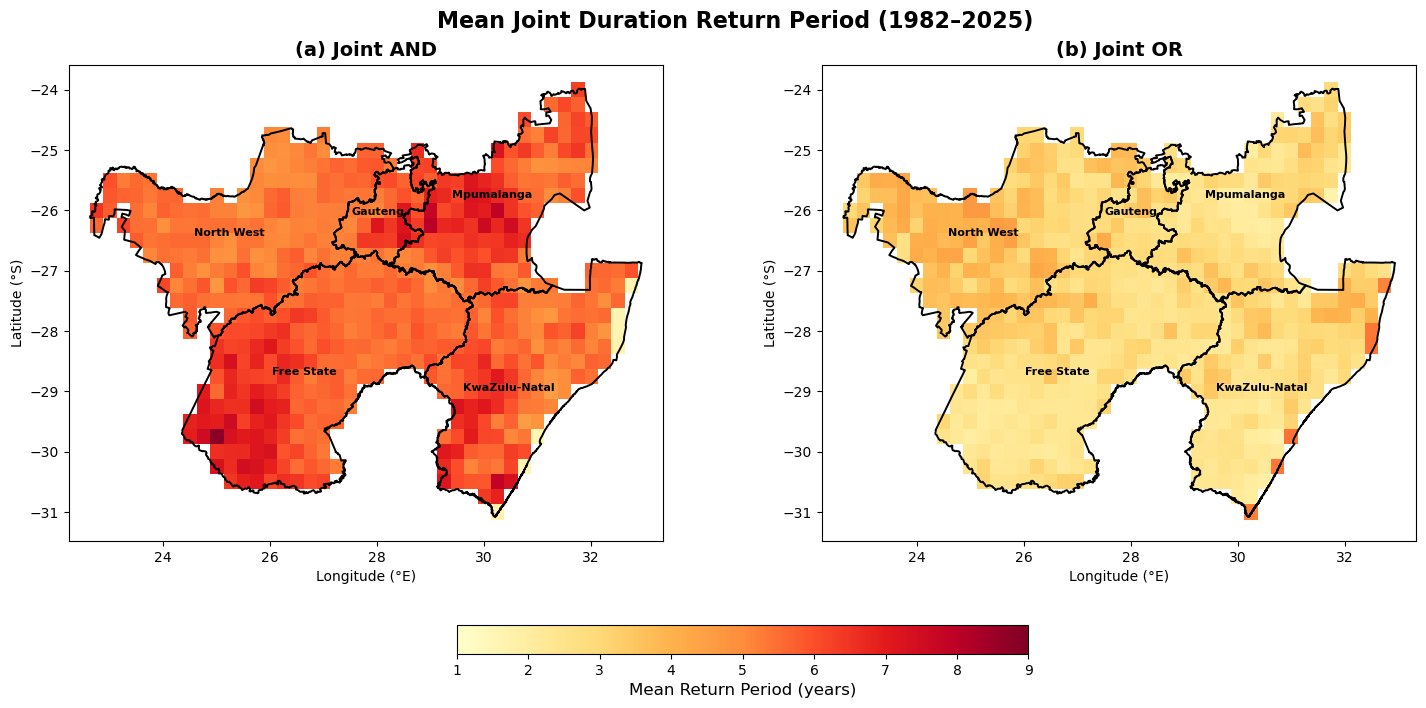


Saved:
C:\Users\franc\mean_duration_return_period_study_provinces.png


In [14]:
import xarray as xr
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point

# ============================================================
# FILES
# ============================================================

rp_file = r"C:\Users\franc\rq1_cdhw_return_periods_1982_2025_corrected.nc"

province_file = (
    r"C:\Users\franc\South_Africa_Provinces"
    r"\South_Africa_Provinces.gpkg"
)

# ============================================================
# LOAD DATA
# ============================================================

ds = xr.open_dataset(rp_file)

provinces = gpd.read_file(province_file)

study_names = [
    "Mpumalanga",
    "North West",
    "Gauteng",
    "Free State",
    "KwaZulu-Natal"
]

study_provinces = provinces[
    provinces["ProvinceName"].isin(study_names)
].copy()

if study_provinces.crs is not None:
    study_provinces = study_provinces.to_crs("EPSG:4326")

# ============================================================
# MEAN RETURN PERIOD OVER 1982-2025
# ============================================================

mean_AND = ds["return_period_AND"].mean(
    dim="harvest_year",
    skipna=True
)

mean_OR = ds["return_period_OR"].mean(
    dim="harvest_year",
    skipna=True
)

# ============================================================
# CREATE MASK FOR THE FIVE PROVINCES
# ============================================================

union_geom = study_provinces.geometry.union_all()

lat = mean_AND["latitude"].values
lon = mean_AND["longitude"].values

lon2d, lat2d = np.meshgrid(lon, lat)

mask = np.zeros(lon2d.shape, dtype=bool)

for i in range(lat2d.shape[0]):
    for j in range(lat2d.shape[1]):
        mask[i, j] = union_geom.covers(
            Point(lon2d[i, j], lat2d[i, j])
        )

AND_masked = mean_AND.where(mask)
OR_masked = mean_OR.where(mask)

# ============================================================
# STUDY-AREA EXTENT
# ============================================================

minx, miny, maxx, maxy = study_provinces.total_bounds

padding = 0.4

# ============================================================
# COMMON COLOUR SCALE
# ============================================================

combined = np.concatenate([
    AND_masked.values[np.isfinite(AND_masked.values)],
    OR_masked.values[np.isfinite(OR_masked.values)]
])

vmin = np.floor(np.nanmin(combined))
vmax = np.ceil(np.nanmax(combined))

print("Colour scale:", vmin, "to", vmax, "years")

# ============================================================
# PLOT
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 7),
    constrained_layout=True
)

# -----------------------------
# AND
# -----------------------------

p1 = axes[0].pcolormesh(
    lon,
    lat,
    AND_masked,
    shading="auto",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax
)

study_provinces.boundary.plot(
    ax=axes[0],
    linewidth=1.4,
    edgecolor="black"
)

axes[0].set_title(
    "(a) Joint AND",
    fontsize=14,
    fontweight="bold"
)

# -----------------------------
# OR
# -----------------------------

p2 = axes[1].pcolormesh(
    lon,
    lat,
    OR_masked,
    shading="auto",
    cmap="YlOrRd",
    vmin=vmin,
    vmax=vmax
)

study_provinces.boundary.plot(
    ax=axes[1],
    linewidth=1.4,
    edgecolor="black"
)

axes[1].set_title(
    "(b) Joint OR",
    fontsize=14,
    fontweight="bold"
)

# ============================================================
# PROVINCE LABELS
# ============================================================

for ax in axes:

    for _, row in study_provinces.iterrows():

        point = row.geometry.representative_point()

        ax.text(
            point.x,
            point.y,
            row["ProvinceName"],
            fontsize=8,
            ha="center",
            va="center",
            fontweight="bold"
        )

    ax.set_xlim(
        minx - padding,
        maxx + padding
    )

    ax.set_ylim(
        miny - padding,
        maxy + padding
    )

    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°S)")

# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    p2,
    ax=axes,
    orientation="horizontal",
    fraction=0.06,
    pad=0.08
)

cbar.set_label(
    "Mean Return Period (years)",
    fontsize=12
)

# ============================================================
# TITLE
# ============================================================

fig.suptitle(
    "Mean Joint Duration Return Period (1982–2025)",
    fontsize=16,
    fontweight="bold"
)

# ============================================================
# SAVE
# ============================================================

output = (
    r"C:\Users\franc"
    r"\mean_duration_return_period_study_provinces.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(output)

In [15]:
import xarray as xr

hw_file = r"C:\Users\franc\south_africa_maize_season_heatwaves_1981_2025_updated.nc"
fd_file = r"C:\Users\franc\flash_drought_events_1982_2025_final.nc"

hw = xr.open_dataset(hw_file, decode_timedelta=False)
fd = xr.open_dataset(fd_file, decode_timedelta=False)

print("=" * 70)
print("HEATWAVE VARIABLES")
print("=" * 70)

for var in hw.data_vars:
    print(var, hw[var].dims, hw[var].shape)

print("\n" + "=" * 70)
print("FLASH DROUGHT VARIABLES")
print("=" * 70)

for var in fd.data_vars:
    print(var, fd[var].dims, fd[var].shape)

HEATWAVE VARIABLES
hw_frequency ('harvest_year', 'latitude', 'longitude') (44, 57, 89)
hw_duration ('harvest_year', 'latitude', 'longitude') (44, 57, 89)
hw_intensity ('harvest_year', 'latitude', 'longitude') (44, 57, 89)

FLASH DROUGHT VARIABLES
fd_frequency ('harvest_year', 'lat', 'lon') (44, 141, 220)
fd_total_duration ('harvest_year', 'lat', 'lon') (44, 141, 220)
fd_max_duration ('harvest_year', 'lat', 'lon') (44, 141, 220)
fd_cumulative_intensity ('harvest_year', 'lat', 'lon') (44, 141, 220)
fd_peak_intensity ('harvest_year', 'lat', 'lon') (44, 141, 220)


In [16]:
freq_AND, freq_OR = calculate_joint_return_periods(
    hw["hw_frequency"],
    fd["fd_frequency"]
)

mean_freq_AND = freq_AND.mean(
    "harvest_year",
    skipna=True
)

mean_freq_OR = freq_OR.mean(
    "harvest_year",
    skipna=True
)

NameError: name 'calculate_joint_return_periods' is not defined

In [17]:
import numpy as np
import xarray as xr
from scipy import stats

def calculate_joint_return_periods(hw_da, fd_da):

    hw_da, fd_da = xr.align(
        hw_da,
        fd_da,
        join="inner"
    )

    def pixel_return_period(hw_axis, fd_axis):

        hw_axis = np.asarray(hw_axis, dtype=float)
        fd_axis = np.asarray(fd_axis, dtype=float)

        valid = (
            np.isfinite(hw_axis)
            &
            np.isfinite(fd_axis)
        )

        result_and = np.full(hw_axis.shape, np.nan)
        result_or = np.full(hw_axis.shape, np.nan)

        x = hw_axis[valid]
        y = fd_axis[valid]

        n = len(x)

        if n < 5:
            return result_and, result_or

        rank_x = stats.rankdata(
            x,
            method="average"
        )

        rank_y = stats.rankdata(
            y,
            method="average"
        )

        U = (rank_x - 0.44) / (n + 0.12)
        V = (rank_y - 0.44) / (n + 0.12)

        t_and = np.full(n, np.nan)
        t_or = np.full(n, np.nan)

        for i in range(n):

            both_less_equal = np.sum(
                (U <= U[i]) &
                (V <= V[i])
            )

            C_uv = both_less_equal / n

            # Joint AND
            prob_and = (
                1 - U[i] - V[i] + C_uv
            )

            if prob_and > 0:
                t_and[i] = 1 / prob_and

            # Joint OR
            prob_or = 1 - C_uv

            if prob_or > 0:
                t_or[i] = 1 / prob_or

        result_and[valid] = t_and
        result_or[valid] = t_or

        return result_and, result_or

    rp_and, rp_or = xr.apply_ufunc(
        pixel_return_period,
        hw_da,
        fd_da,
        input_core_dims=[
            ["harvest_year"],
            ["harvest_year"]
        ],
        output_core_dims=[
            ["harvest_year"],
            ["harvest_year"]
        ],
        vectorize=True,
        output_dtypes=[float, float]
    )

    return rp_and, rp_or